# BankSim — Data Understanding

This notebook documents exploratory analysis of the synthetic BankSim transaction dataset, including fraud prevalence, category-level patterns, transaction amounts, and simulation-step behavior.

**Recovery provenance:** This publication candidate combines an earlier Jupyter checkpoint with recoverable cells from a damaged notebook. The missing category-level summary calculations were reconstructed from the dataset, rather than recovered verbatim. Existing analytical interpretations and saved outputs have been preserved. The reconstruction has been executed locally by the project author, but a clean-kernel, top-to-bottom reproduction test is still recommended before publication.

**Working directory:** Open and execute this notebook from the repository's `notebooks/` directory. The raw dataset is expected at `../data/raw/bs140513_032310.csv` and is not included in the GitHub repository.


In [1]:
from pathlib import Path
import pandas as pd

data_path = Path("../data/raw/bs140513_032310.csv")


print(data_path.exists())
print(data_path.stat().st_size)

True
48986035


In [2]:
df = pd.read_csv(data_path)

print(df.shape)
print(df.columns.tolist())

(594643, 10)
['step', 'customer', 'age', 'gender', 'zipcodeOri', 'merchant', 'zipMerchant', 'category', 'amount', 'fraud']


In [3]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 594643 entries, 0 to 594642
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   step         594643 non-null  int64  
 1   customer     594643 non-null  object 
 2   age          594643 non-null  object 
 3   gender       594643 non-null  object 
 4   zipcodeOri   594643 non-null  object 
 5   merchant     594643 non-null  object 
 6   zipMerchant  594643 non-null  object 
 7   category     594643 non-null  object 
 8   amount       594643 non-null  float64
 9   fraud        594643 non-null  int64  
dtypes: float64(1), int64(2), object(7)
memory usage: 45.4+ MB
None


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 594643 entries, 0 to 594642
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   step         594643 non-null  int64  
 1   customer     594643 non-null  object 
 2   age          594643 non-null  object 
 3   gender       594643 non-null  object 
 4   zipcodeOri   594643 non-null  object 
 5   merchant     594643 non-null  object 
 6   zipMerchant  594643 non-null  object 
 7   category     594643 non-null  object 
 8   amount       594643 non-null  float64
 9   fraud        594643 non-null  int64  
dtypes: float64(1), int64(2), object(7)
memory usage: 45.4+ MB


In [5]:
df.head()

,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
0,0,'C1093826151','4','M','28007','M348934600','28007','es_transportation',4.55,0
1,0,'C352968107','2','M','28007','M348934600','28007','es_transportation',39.68,0
2,0,'C2054744914','4','F','28007','M1823072687','28007','es_transportation',26.89,0
3,0,'C1760612790','3','M','28007','M348934600','28007','es_transportation',17.25,0
4,0,'C757503768','5','M','28007','M348934600','28007','es_transportation',35.72,0


In [6]:
df.nunique()

step             180
customer        4112
age                8
gender             4
zipcodeOri         1
merchant          50
zipMerchant        1
category          15
amount         23767
fraud              2
dtype: int64

In [7]:
for col in ["step", "age", "gender", "zipcodeOri",
            "zipMerchant", "category", "fraud"]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).sort_index())


step:
step
0      2430
1      2424
2      2462
3      2499
4      2532
       ... 
175    3774
176    3721
177    3758
178    3743
179    3709
Name: count, Length: 180, dtype: int64

age:
age
'0'      2452
'1'     58131
'2'    187310
'3'    147131
'4'    109025
'5'     62642
'6'     26774
'U'      1178
Name: count, dtype: int64

gender:
gender
'E'      1178
'F'    324565
'M'    268385
'U'       515
Name: count, dtype: int64

zipcodeOri:
zipcodeOri
'28007'    594643
Name: count, dtype: int64

zipMerchant:
zipMerchant
'28007'    594643
Name: count, dtype: int64

category:
category
'es_barsandrestaurants'      6373
'es_contents'                 885
'es_fashion'                 6454
'es_food'                   26254
'es_health'                 16133
'es_home'                    1986
'es_hotelservices'           1744
'es_hyper'                   6098
'es_leisure'                  499
'es_otherservices'            912
'es_sportsandtoys'           4002
'es_tech'                    2370
'es_t

In [8]:
fraud_rate = df["fraud"].mean()

print(f"Fraud rate: {fraud_rate:.6f}")
print(f"Fraud percentage: {100 * fraud_rate:.3f}%")

Fraud rate: 0.012108
Fraud percentage: 1.211%


In [9]:
print("Number of customers:", df["customer"].nunique())
print("Number of merchants:", df["merchant"].nunique())

print("\nFirst 5 customer IDs:")
print(df["customer"].head().tolist())

print("\nFirst 5 merchant IDs:")
print(df["merchant"].head().tolist())

Number of customers: 4112
Number of merchants: 50

First 5 customer IDs:
["'C1093826151'", "'C352968107'", "'C2054744914'", "'C1760612790'", "'C757503768'"]

First 5 merchant IDs:
["'M348934600'", "'M348934600'", "'M1823072687'", "'M348934600'", "'M348934600'"]


In [10]:
df["amount"].describe()

count    594643.000000
mean         37.890135
std         111.402831
min           0.000000
25%          13.740000
50%          26.900000
75%          42.540000
max        8329.960000
Name: amount, dtype: float64

In [11]:
duplicate_rows = df.duplicated().sum()
print("Exact duplicate rows:", duplicate_rows)

Exact duplicate rows: 0


In [12]:
print("Minimum step:", df["step"].min())
print("Maximum step:", df["step"].max())

Minimum step: 0
Maximum step: 179


In [13]:
print(pd.crosstab(df["gender"], df["age"]))

age      '0'    '1'     '2'    '3'    '4'    '5'    '6'   'U'
gender                                                       
'E'        0      0       0      0      0      0      0  1178
'F'     1857  32836  104754  78432  58646  34101  13939     0
'M'      595  25117   82392  68526  50379  28541  12835     0
'U'        0    178     164    173      0      0      0     0


---

## Reconstructed category-level statistics

The original notebook was damaged between the initial dataset exploration and the later category-level visualizations. The following category summary was **reconstructed**, using the original BankSim dataset and the downstream variables required by the recovered analysis. It is not represented as a verbatim recovery of the missing code.

For each transaction category, `transactions` counts rows, `fraud_count` sums binary fraud labels, and `fraud_percentage` is 100 times the category-specific fraud proportion. `plot_data` is a copy used for visualization.

---

In [14]:
# Reconstruct category-level fraud statistics
category_fraud = (
    df.groupby("category")
      .agg(
          transactions=("fraud", "size"),
          fraud_count=("fraud", "sum")
      )
)

category_fraud["fraud_percentage"] = (
    100 * category_fraud["fraud_count"]
    / category_fraud["transactions"]
)

# Data used for the scatter plot
plot_data = category_fraud.copy()

print(category_fraud)

                         transactions  fraud_count  fraud_percentage
category                                                            
'es_barsandrestaurants'          6373          120          1.882944
'es_contents'                     885            0          0.000000
'es_fashion'                     6454          116          1.797335
'es_food'                       26254            0          0.000000
'es_health'                     16133         1696         10.512614
'es_home'                        1986          302         15.206445
'es_hotelservices'               1744          548         31.422018
'es_hyper'                       6098          280          4.591669
'es_leisure'                      499          474         94.989980
'es_otherservices'                912          228         25.000000
'es_sportsandtoys'               4002         1982         49.525237
'es_tech'                        2370          158          6.666667
'es_transportation'            505

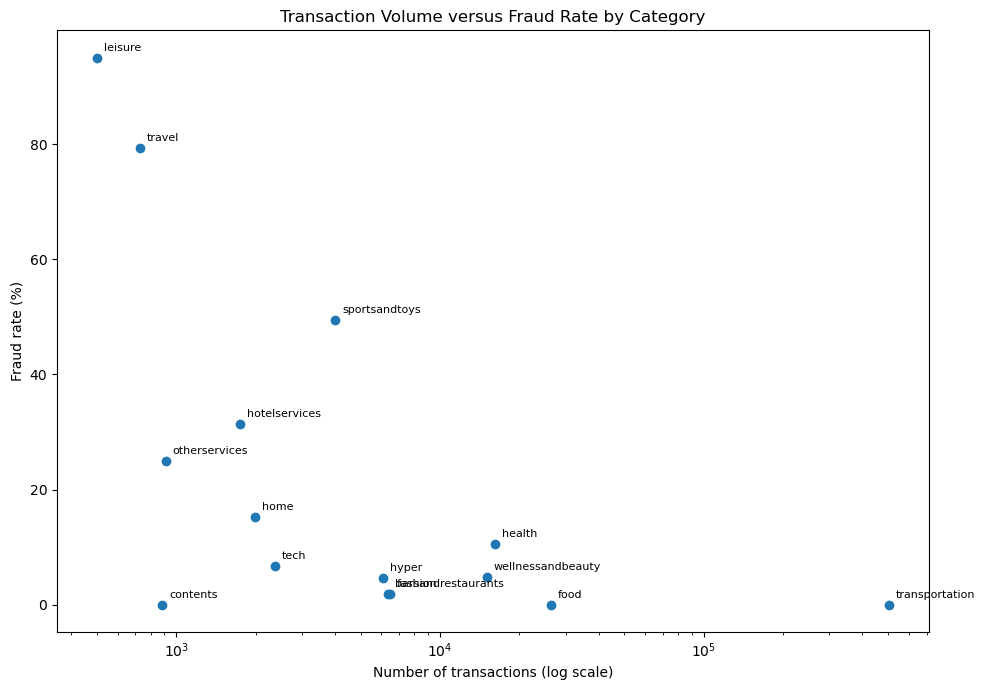

In [15]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 7))

plt.scatter(
    plot_data["transactions"],
    plot_data["fraud_percentage"]
)

for category, row in plot_data.iterrows():
    plt.annotate(
        category.strip("'").replace("es_", ""),
        (row["transactions"], row["fraud_percentage"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.xscale("log")

plt.xlabel("Number of transactions (log scale)")
plt.ylabel("Fraud rate (%)")
plt.title("Transaction Volume versus Fraud Rate by Category")
plt.tight_layout()
plt.show()

#### Interpretation

Transaction volumes vary by several orders of magnitude across categories, with `transportation` overwhelmingly dominating the dataset. A logarithmic x-axis is therefore used to preserve visibility of the lower-volume categories without excluding the dominant category.

The figure shows that high observed fraud rates are concentrated primarily among several relatively low-volume categories. Conversely, the highest-volume category, `transportation`, contains no observed fraud cases. Category volume alone therefore does not explain the observed fraud prevalence.

The strong category-specific pattern further suggests that transaction category may provide substantial predictive information in BankSim. Because the dataset is simulation-based, however, these relationships should not be assumed to transfer directly to real-world transaction populations.

### 4.2 Distribution of Fraud Cases Across Categories

Within-category fraud rate measures fraud prevalence, but it does not show how the total observed fraud cases are distributed across categories. This analysis therefore measures each category's contribution to the 7,200 fraudulent transactions in the dataset.

In [16]:
fraud_distribution = category_fraud[
    ["transactions", "fraud_count", "fraud_percentage"]
].copy()

fraud_distribution["share_of_all_fraud"] = (
    100
    * fraud_distribution["fraud_count"]
    / fraud_distribution["fraud_count"].sum()
)

fraud_distribution = fraud_distribution.sort_values(
    "fraud_count",
    ascending=False
)

fraud_distribution

,transactions,fraud_count,fraud_percentage,share_of_all_fraud
category,,,,
'es_sportsandtoys',4002,1982,49.525237,27.527778
'es_health',16133,1696,10.512614,23.555556
'es_wellnessandbeauty',15086,718,4.759380,9.972222
'es_travel',728,578,79.395604,8.027778
'es_hotelservices',1744,548,31.422018,7.611111
'es_leisure',499,474,94.989980,6.583333
'es_home',1986,302,15.206445,4.194444
'es_hyper',6098,280,4.591669,3.888889
'es_otherservices',912,228,25.000000,3.166667


#### Interpretation

The distribution of fraud cases differs substantially from the ranking based on within-category fraud rates.

`sportsandtoys` contributes approximately 27.53% of all observed fraud cases and `health` approximately 23.56%. Together, these two categories account for about 51.08% of the 7,200 fraudulent transactions.

This illustrates the distinction between fraud prevalence and fraud volume. For example, `leisure` has the highest within-category fraud rate (approximately 95.0%) but contributes only about 6.58% of all fraud cases because the category contains relatively few transactions. In contrast, `health` has a much lower fraud rate (approximately 10.51%) but contributes approximately 23.56% of all fraud cases because of its larger transaction volume.

Thus, category-level fraud behavior should be evaluated using both within-category fraud rates and contributions to the total number of fraud cases.

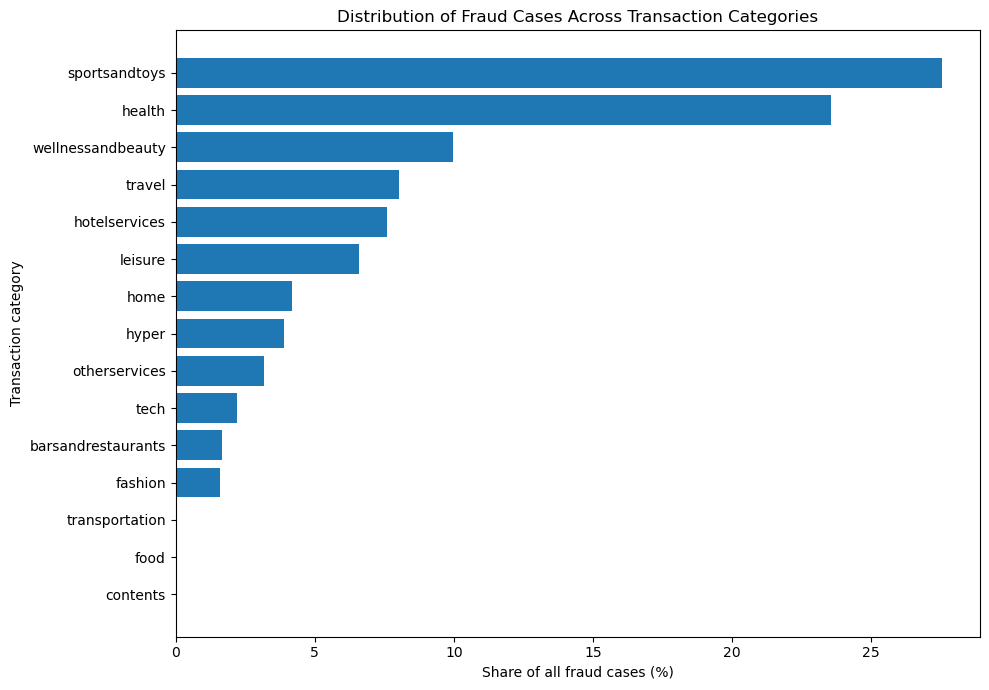

In [17]:
fraud_plot = fraud_distribution.sort_values(
    "share_of_all_fraud",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    fraud_plot.index.str.strip("'").str.replace("es_", "", regex=False),
    fraud_plot["share_of_all_fraud"]
)

plt.xlabel("Share of all fraud cases (%)")
plt.ylabel("Transaction category")
plt.title("Distribution of Fraud Cases Across Transaction Categories")
plt.tight_layout()
plt.show()

In [18]:
print(
    f"Total share of fraud cases: "
    f"{fraud_distribution['share_of_all_fraud'].sum():.2f}%"
)

Total share of fraud cases: 100.00%


### 4.3 Transaction Amount and Fraud

Transaction amount may contain useful information for distinguishing fraudulent from non-fraudulent transactions. However, the overall amount distribution is strongly right-skewed, and unusually large transactions should not automatically be treated as erroneous observations.

This section first compares descriptive statistics of transaction amounts for fraudulent and non-fraudulent transactions before selecting appropriate visualizations or considering any treatment of extreme values.

In [19]:
amount_by_fraud = (
    df.groupby("fraud")["amount"]
      .describe(
          percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
      )
)

amount_by_fraud

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
fraud,,,,,,,,,,,,
0,587443.0,31.847230,31.470876,0.00,0.5600,2.7600,13.59,26.610,41.8950,72.81,153.7574,2144.86
1,7200.0,530.926551,835.587112,0.03,6.3088,30.9455,159.98,319.175,548.9775,1889.59,4774.7894,8329.96


In [20]:
amount_summary = (
    df.groupby("fraud")["amount"]
      .agg(
          count="count",
          mean="mean",
          median="median",
          total_amount="sum"
      )
)

amount_summary["share_of_transaction_count"] = (
    100 * amount_summary["count"] / len(df)
)

amount_summary["share_of_total_amount"] = (
    100 * amount_summary["total_amount"] / df["amount"].sum()
)

amount_summary

,count,mean,median,total_amount,share_of_transaction_count,share_of_total_amount
fraud,,,,,,
0,587443,31.847230,26.610,18708432.56,98.789189,83.033804
1,7200,530.926551,319.175,3822671.17,1.210811,16.966196


#### Interpretation

Transaction amounts differ substantially between fraudulent and non-fraudulent transactions in BankSim.

The median fraudulent transaction amount is approximately 319.18, compared with 26.61 for non-fraudulent transactions. The corresponding means are approximately 530.93 and 31.85, respectively. The considerably larger means relative to medians, particularly for fraudulent transactions, indicate substantial right-skewness and motivate examination of the full distributions rather than relying on averages alone.

The upper tails also differ markedly. The 95th percentile is approximately 1,889.59 for fraudulent transactions compared with 72.81 for non-fraudulent transactions, while the respective 99th percentiles are approximately 4,774.79 and 153.76.

Although fraudulent transactions constitute only approximately 1.211% of all transactions, they account for approximately 16.97% of the total transaction amount observed in the dataset. Thus, transaction-count prevalence and monetary-volume exposure provide substantially different views of the fraud class.

These descriptive results indicate a strong association between transaction amount and the fraud label in BankSim. They do not, by themselves, establish a causal relationship or justify removing large transaction amounts as outliers.

#### Amount Distribution by Fraud Class

Because transaction amounts are strongly right-skewed and span a wide numerical range, the raw amount scale can obscure the main distributional structure. For visualization only, the transformation $\log(1+\mathrm{amount})$ is used. This transformation retains zero-valued transactions and compresses the upper tail without removing observations.

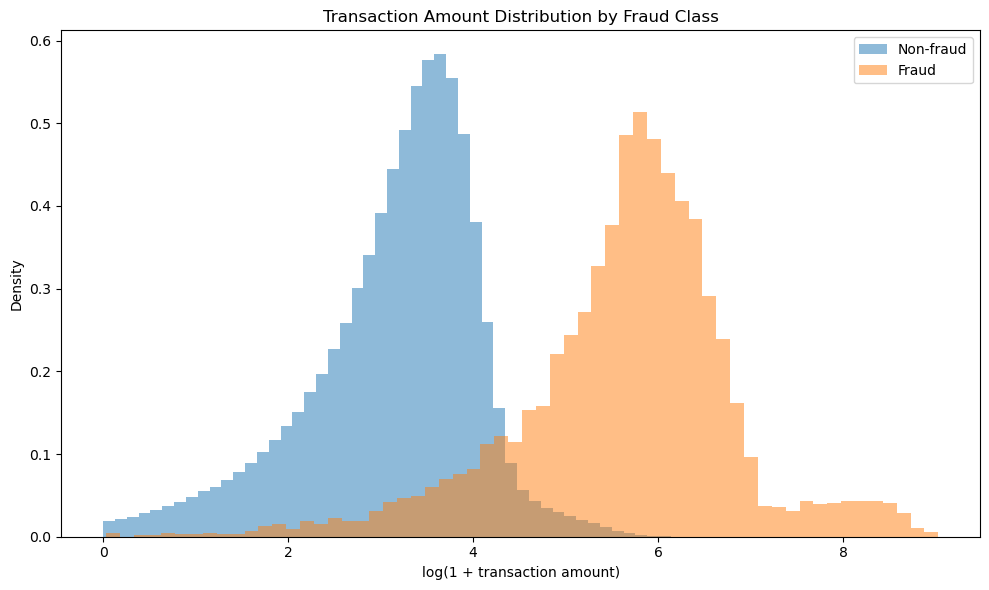

In [21]:
import numpy as np
import matplotlib.pyplot as plt

nonfraud_amount = np.log1p(
    df.loc[df["fraud"] == 0, "amount"]
)

fraud_amount = np.log1p(
    df.loc[df["fraud"] == 1, "amount"]
)

plt.figure(figsize=(10, 6))

plt.hist(
    nonfraud_amount,
    bins=60,
    density=True,
    alpha=0.5,
    label="Non-fraud"
)

plt.hist(
    fraud_amount,
    bins=60,
    density=True,
    alpha=0.5,
    label="Fraud"
)

plt.xlabel("log(1 + transaction amount)")
plt.ylabel("Density")
plt.title("Transaction Amount Distribution by Fraud Class")
plt.legend()
plt.tight_layout()
plt.show()

#### Interpretation

The log-transformed amount distributions show a substantial shift toward larger transaction amounts for fraudulent transactions. Non-fraudulent transactions are concentrated primarily at lower amounts, whereas the fraud distribution is centered at considerably higher amounts and extends further into the upper tail.

The two distributions nevertheless overlap. Therefore, transaction amount appears to provide substantial discriminatory information in BankSim, but amount alone does not perfectly separate fraudulent from non-fraudulent transactions.

The fraud distribution also exhibits a pronounced upper tail, consistent with the large differences observed in its mean, upper percentiles, and maximum. The use of $\log(1+\mathrm{amount})$ makes these distributional differences visible without removing zero-valued or high-value observations.

As with the category results, the strength of the observed relationship should be interpreted in the context of BankSim's simulation-based data-generating process and should not be assumed to represent the same relationship in real payment systems.

### 4.4 Fraud Behavior Over Time

The `step` variable provides the ordering of transactions across 180 simulation steps. Examining fraud behavior over this sequence is important for identifying temporal variation and for informing the later validation strategy.

For each step, the analysis considers transaction volume, number of fraud cases, and fraud rate.

In [22]:
step_fraud = (
    df.groupby("step")["fraud"]
      .agg(
          transactions="count",
          fraud_count="sum",
          fraud_rate="mean"
      )
)

step_fraud["fraud_percentage"] = (
    100 * step_fraud["fraud_rate"]
)

step_fraud

,transactions,fraud_count,fraud_rate,fraud_percentage
step,,,,
0,2430,40,0.016461,1.646091
1,2424,40,0.016502,1.650165
2,2462,40,0.016247,1.624695
3,2499,40,0.016006,1.600640
4,2532,40,0.015798,1.579779
...,...,...,...,...
175,3774,40,0.010599,1.059883
176,3721,40,0.010750,1.074980
177,3758,40,0.010644,1.064396


In [23]:
print("Number of steps:", len(step_fraud))
print("Total transactions:", step_fraud["transactions"].sum())
print("Total fraud cases:", step_fraud["fraud_count"].sum())

print("\nFraud percentage across steps:")
print(step_fraud["fraud_percentage"].describe())

Number of steps: 180
Total transactions: 594643
Total fraud cases: 7200

Fraud percentage across steps:
count    180.000000
mean       1.226807
std        0.147913
min        1.059883
25%        1.108878
50%        1.178724
75%        1.308367
max        1.650165
Name: fraud_percentage, dtype: float64


In [24]:
print("Unique fraud counts per step:")
print(step_fraud["fraud_count"].unique())

print("\nFraud-count frequency:")
print(step_fraud["fraud_count"].value_counts().sort_index())

print(
    "\nAll steps contain the same number of fraud cases:",
    step_fraud["fraud_count"].nunique() == 1
)

Unique fraud counts per step:
[40]

Fraud-count frequency:
fraud_count
40    180
Name: count, dtype: int64

All steps contain the same number of fraud cases: True


In [25]:
print(
    "Correlation between transaction volume and fraud percentage:",
    step_fraud["transactions"].corr(
        step_fraud["fraud_percentage"]
    )
)

Correlation between transaction volume and fraud percentage: -0.9933918546453789


#### Temporal Structure of the Fraud Label

A notable structural property is that every one of the 180 simulation steps contains exactly 40 fraudulent transactions, giving a total of 7,200 fraud cases.

Consequently, variation in the step-level fraud rate is driven by variation in the total number of transactions per step rather than by variation in the number of observed fraud cases. The correlation between transaction volume and step-level fraud percentage is approximately -0.9934, but this strong negative association is largely mechanical because the numerator of the fraud-rate calculation is fixed at 40 for every step.

Therefore, a decline in step-level fraud percentage should not be interpreted as evidence that the underlying number of fraud cases decreases over time or that higher transaction volume causes lower fraud risk. This structure is also relevant when designing the later validation strategy because the temporal behavior partly reflects the BankSim simulation mechanism.

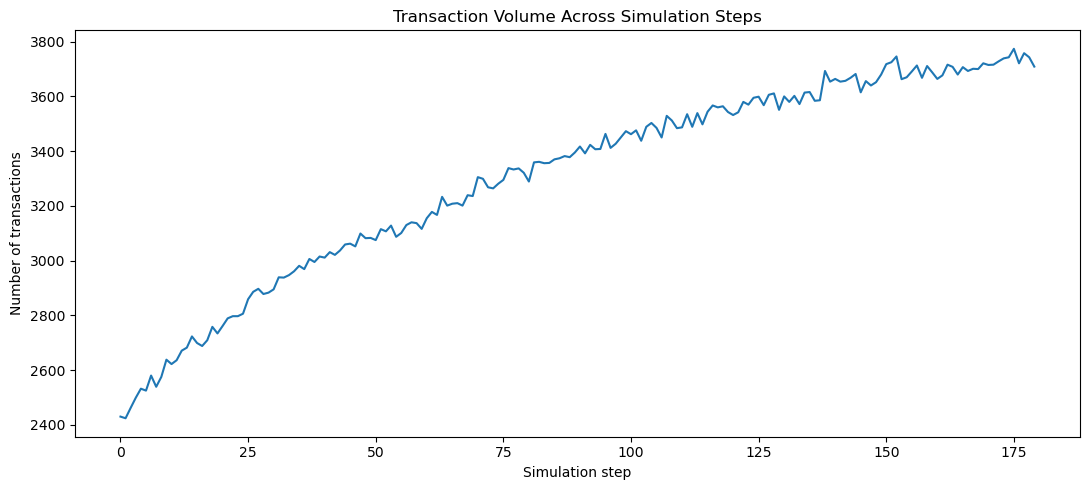

In [26]:
plt.figure(figsize=(11, 5))

plt.plot(
    step_fraud.index,
    step_fraud["transactions"]
)

plt.xlabel("Simulation step")
plt.ylabel("Number of transactions")
plt.title("Transaction Volume Across Simulation Steps")
plt.tight_layout()
plt.show()